# EDA v2 — Phân phối, ngoại lệ và RFM thử nghiệm

Mục tiêu là hiểu đuôi phân phối và mức ảnh hưởng đến phân cụm; giữ mọi khách giá trị cao
trừ khi có bằng chứng nghiệp vụ cần xử lý. Notebook tự đọc workbook và chạy trong một
kernel mới, không cần kết quả hay code từ notebook v1.

Nguồn `data/raw/online_retail_II.xlsx`, cả hai sheet, 01/12/2009–09/12/2011; giá GBP,
thời gian không có múi giờ. Dùng cùng chính sách pipeline và cửa sổ `[01/12/2009, 10/12/2011)`.
Kết quả là khảo sát, chưa là bảng đặc trưng chính thức.

Báo cáo đầy đủ: [bao_cao_qua_trinh_eda.md](../../reports/bao_cao_qua_trinh_eda.md).
Chọn **Restart Kernel → Run All** để tính lại; các nhận xét số dưới đây thuộc phiên bản
workbook được nhận diện bằng checksum hiển thị trong notebook.

## 0. Thư viện, cửa sổ và hàm kiểm tra

Mã EDA nằm trực tiếp trong notebook. Chạy từ đầu đến cuối trong một kernel mới; không cần notebook khác hoặc các file Python hỗ trợ EDA. Các API `src/` hiện có của nhóm được tái sử dụng, không chỉnh sửa.

In [1]:
from __future__ import annotations
from pathlib import Path
import hashlib
import importlib.metadata
import platform
import sys

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown, Image

# Run All works from this directory, project/, or the repository root.
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents]
               if (p / "data/raw/online_retail_II.xlsx").is_file()
               or (p / "project/data/raw/online_retail_II.xlsx").is_file())
if (PROJECT / "project/data/raw/online_retail_II.xlsx").is_file():
    PROJECT = PROJECT / "project"
PROJECT = PROJECT.resolve()
sys.path.insert(0, str(PROJECT))
from src.features import build_customer_behavior_features, aggregate_purchase_orders

ORIGINAL_COLUMNS = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "Customer ID", "Country"]
WINDOW_START = "2009-12-01"
REFERENCE_DATE = "2011-12-10"
EXPORT_TABLES = ()  # Diagnostic notebook: no CSV exports.
BLUE, ORANGE, GREY = "#245C88", "#C27623", "#65727C"
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")

def checksum(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as stream:
        for chunk in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

def identifier(values: pd.Series) -> pd.Series:
    return values.astype("string").str.strip().str.replace(r"(?<=\d)\.0$", "", regex=True).replace("", pd.NA)

### Tái hiện chính sách tiền xử lý đã khảo sát

**Mốc chính sách của báo cáo:** các kết quả làm sạch, khảo sát khách hàng và RFM trong bản EDA này dùng chính sách tại commit `1c7ce32`. `main` đã có thay đổi tiền xử lý tại commit `d17492d`; các con số ở đây chưa đánh giá chính sách mới đó. Notebook giữ mã tái hiện chính sách cũ ngay trong một ô riêng để chạy độc lập, không sửa hoặc gọi API cũ đã bị xóa khỏi `src/preprocessing.py`. Các mô tả “hiện tại/current” trong kết quả đã lưu được hiểu tại mốc `1c7ce32`.

In [2]:
# Historical preprocessing policy replay, frozen at commit 1c7ce32.
# This cell audits the recorded EDA baseline; it is not the current team pipeline.
POLICY_COMMIT = "1c7ce32"
POLICY_SOURCE_SHA256 = "fe3cb23a1fe5ea84c69624053774ceb8bb9d48c48f6d512d5019970f4d7bcb8b"

SERVICE_CODES = {
    "POST", "DOT", "M", "C2", "C3", "D", "S", "B", "BANK CHARGES",
    "ADJUST", "ADJUST2", "AMAZONFEE", "CRUK", "TEST001", "TEST002",
}


def standardize(df: pd.DataFrame) -> pd.DataFrame:
    """Chuẩn hóa chuỗi: bỏ khoảng trắng, viết hoa mã hàng, đổi tên cột."""
    out = df.copy()
    out["Invoice"] = out["Invoice"].astype(str).str.strip().str.upper()
    out["StockCode"] = out["StockCode"].astype(str).str.strip().str.upper()
    out["Description"] = out["Description"].astype("string").str.strip()
    out["Country"] = out["Country"].astype("string").str.strip()
    return out.rename(columns={"Customer ID": "CustomerID"})


def reversed_sale_mask(sales: pd.DataFrame, cancels: pd.DataFrame) -> pd.Series:
    """Đánh dấu dòng bán đã bị hủy nguyên vẹn (cùng khách, mã hàng, số lượng, đơn giá).

    Khớp theo từng cặp một: mỗi dòng hủy chỉ "triệt tiêu" tối đa một dòng bán
    xảy ra trước nó.
    """
    key = ["CustomerID", "StockCode", "Price"]
    s = sales[key + ["Quantity", "InvoiceDate"]].copy()
    c = cancels[key + ["Quantity", "InvoiceDate"]].copy()
    c["Quantity"] = -c["Quantity"]
    s["rank"] = s.groupby(key + ["Quantity"]).cumcount()
    c["rank"] = c.groupby(key + ["Quantity"]).cumcount()
    merged = s.reset_index().merge(
        c, on=key + ["Quantity", "rank"], how="left", suffixes=("", "_cancel")
    )
    hit = merged["InvoiceDate_cancel"].notna() & (
        merged["InvoiceDate_cancel"] >= merged["InvoiceDate"]
    )
    return pd.Series(hit.to_numpy(), index=merged["index"]).reindex(sales.index).fillna(False)


def clean_transactions(raw: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Áp dụng toàn bộ quy tắc tiền xử lý.

    Trả về `(sales, cancellations, log)`:
    - `sales`: dòng bán hợp lệ có mã khách hàng (đầu vào cho RFM);
    - `cancellations`: dòng hóa đơn hủy có mã khách hàng (dùng cho đặc trưng hoàn trả);
    - `log`: số dòng bị loại ở từng bước.
    """
    log: list[tuple[str, int]] = [("Dữ liệu gốc sau khi gộp sheet", len(raw))]
    df = standardize(raw)

    def step(name: str, frame: pd.DataFrame) -> pd.DataFrame:
        log.append((name, len(frame)))
        return frame

    cols = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate",
            "Price", "CustomerID", "Country"]
    df = step("Bỏ dòng trùng hoàn toàn", df.drop_duplicates(subset=cols))
    df = step("Bỏ dòng thiếu CustomerID", df.dropna(subset=["CustomerID"]))
    df = df.assign(CustomerID=df["CustomerID"].astype(int))
    df = step("Bỏ mã hàng dịch vụ/phí/thử nghiệm", df[~df["StockCode"].isin(SERVICE_CODES)])

    is_cancel = df["Invoice"].str.startswith("C")
    cancels = df[is_cancel & (df["Quantity"] < 0)]
    sales = df[~is_cancel]
    log.append(("Tách hóa đơn hủy (tiền tố C) sang bảng riêng", len(sales)))
    sales = step("Bỏ dòng bán có Quantity <= 0 hoặc Price <= 0", sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)])
    cancels = cancels[cancels["Price"] > 0]

    sales = sales.assign(LineValue=(sales["Quantity"] * sales["Price"]).round(2))
    cancels = cancels.assign(LineValue=(cancels["Quantity"] * cancels["Price"]).round(2))
    mask = reversed_sale_mask(sales, cancels)
    sales = step("Bỏ dòng bán đã bị hủy nguyên vẹn (đơn lỗi/ngoại lai)", sales[~mask])

    sales = sales.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
    cancels = cancels.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
    return sales, cancels, pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])

In [3]:
def descriptive(frame: pd.DataFrame, columns: list[str], population: str) -> pd.DataFrame:
    records = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce")
        finite = values[np.isfinite(values)]
        q1, median, q3, p95, p99 = finite.quantile([.25, .5, .75, .95, .99])
        iqr = q3 - q1
        lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        below, above = int(finite.lt(lower).sum()), int(finite.gt(upper).sum())
        records.append(dict(population=population, variable=column, count=int(finite.count()), missing=int(values.isna().sum()),
                            mean=finite.mean(), median=median, minimum=finite.min(), maximum=finite.max(),
                            q1=q1, q3=q3, iqr=iqr, p95=p95, p99=p99, std=finite.std(), skewness=finite.skew(),
                            iqr_lower=lower, iqr_upper=upper, below_iqr=below, above_iqr=above,
                            outside_iqr=below + above, outside_iqr_pct=100 * (below + above) / len(finite) if len(finite) else np.nan,
                            denominator=int(len(finite))))
    return pd.DataFrame(records)



def table(name, limit=15):
    frame = tables[name]
    display(Markdown(f"**{name}** — {len(frame):,} dòng kết quả."))
    if name in EXPORT_TABLES:
        display(Markdown(f"[CSV bàn giao]({OUTPUT_LINK}/tables/{name}.csv)"))
    else:
        display(Markdown(f"Bảng giữ trong biến `tables[\"{name}\"]`; không xuất CSV trung gian."))
    if name.startswith("outlier_"):
        columns = ["population", "variable", "count", "median", "q1", "q3", "iqr", "p95", "p99", "maximum", "outside_iqr", "outside_iqr_pct"]
    elif name in {"descriptive_transactions", "feature_profile", "rfm_profile"}:
        columns = ["population", "variable", "count", "missing", "mean", "median", "minimum", "maximum", "std", "skewness"]
    elif name == "customer_behavior":
        columns = ["Customer ID", "n_orders", "total_purchase_value", "avg_order_value", "n_stock_codes_candidate", "avg_purchase_gap_days", "return_rate"]
    else:
        columns = list(frame.columns)
    display(frame.loc[:, [column for column in columns if column in frame]].head(limit))
    if len(frame) > limit:
        display(Markdown(f"Đang xem {limit:,}/{len(frame):,} dòng. Sau Run All, dùng `tables[\"{name}\"]` để xem đầy đủ."))

### Đọc dữ liệu gốc và ghi nhận phiên bản

Đọc cả hai sheet; không đọc bảng kết quả có sẵn của notebook khác.

In [4]:
project = PROJECT
NOTEBOOK_NAME = "eda_v2_outlier.ipynb"
code_paths = [PROJECT / "src/preprocessing.py", PROJECT / "src/features.py"]
code_before = {path.relative_to(PROJECT).as_posix(): checksum(path) for path in code_paths}
OUTPUT_LINK = "../../experiments/eda_rebuild/outlier_standalone"

source = project / "data/raw/online_retail_II.xlsx"
figure_dir = project / "notebooks/01_eda/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
source_before = checksum(source)
print("Reading all workbook sheets (source read-only)...", flush=True)
sheets = pd.read_excel(source, sheet_name=None, engine="openpyxl")
if len(sheets) != 2 or any(list(part.columns) != ORIGINAL_COLUMNS for part in sheets.values()):
    raise ValueError("Expected two sheets with eight original columns; inspect changed input first.")
tables: dict[str, pd.DataFrame] = {}
summary = {}
figures = []
raw = pd.concat([part.assign(Sheet=name) for name, part in sheets.items()], ignore_index=True)
original = raw.loc[:, ORIGINAL_COLUMNS]

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 11,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.grid": False,
                     "savefig.facecolor": "white"})
def save(fig, name, title, population, table_names, notebook="eda_v1.ipynb"):
    fig.savefig(figure_dir / name, dpi=180, bbox_inches="tight")
    plt.close(fig)
    figures.append(dict(name=name, title=title, population=population, table_names=table_names, notebook=NOTEBOOK_NAME))
    display(Image(filename=str(figure_dir / name), width=1100))
def count_format(ax, axis="y"):
    def compact(x, _):
        if abs(x) >= 1_000_000:
            return f"{x/1_000_000:g}m"
        if abs(x) >= 1_000:
            return f"{x/1_000:g}k"
        return f"{x:,.0f}"
    formatter = FuncFormatter(compact)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(formatter)

Reading all workbook sheets (source read-only)...


## 1. Tập dữ liệu dùng cho khảo sát

Tập thô giữ C/âm/trùng; tập mua được tính lại qua `clean_transactions` trong bộ nhớ.
Trên nguồn đã kiểm tra, có 1.067.371 dòng thô và 770.606 dòng mua của 5.839 khách.
Không chạy cell ghi dữ liệu của notebook tiền xử lý; không sửa module nguồn của nhóm.

Ghép hủy vẫn là heuristic, loại phí theo danh sách hiện có chưa đồng nghĩa mọi mã còn
lại đã là sản phẩm. Các giới hạn đó đi theo cả thống kê ngoại lệ và RFM.

In [5]:
raw["LineValue"] = raw.Quantity * raw.Price
raw["Invoice"] = identifier(raw.Invoice)
raw["StockCode"] = identifier(raw.StockCode)
raw["is_c"] = raw.Invoice.str.upper().str.startswith("C",na=False)
pipeline_input = pd.concat([part.assign(Sheet=name) for name,part in sheets.items()],ignore_index=True)
clean, cancel, pipeline_log = clean_transactions(pipeline_input)
clean_exact_total = float((clean.Quantity * clean.Price).sum())
rounded_total = float(clean.LineValue.sum())
stored_hashes = {path.relative_to(PROJECT).as_posix():checksum(path) for path in (PROJECT / "data/processed").glob("*") if path.is_file()}
display(pipeline_log)
display(Markdown(f"**Phạm vi đã tính lại:** {len(raw):,} dòng thô; "
                 f"{len(clean):,} dòng mua và {clean.CustomerID.nunique():,} khách sau pipeline."))

,Bước,Số dòng còn lại
0,Dữ liệu gốc sau khi gộp sheet,1067371
1,Bỏ dòng trùng hoàn toàn,1033036
2,Bỏ dòng thiếu CustomerID,797885
3,Bỏ mã hàng dịch vụ/phí/thử nghiệm,794244
4,Tách hóa đơn hủy (tiền tố C) sang bảng riêng,776657
5,Bỏ dòng bán có Quantity <= 0 hoặc Price <= 0,776596
6,Bỏ dòng bán đã bị hủy nguyên vẹn (đơn lỗi/ngoại lai),770606


**Phạm vi đã tính lại:** 1,067,371 dòng thô; 770,606 dòng mua và 5,839 khách sau pipeline.

## 2. Phân phối và IQR ở cấp dòng

Thống kê trên toàn miền; ngoài râu = x<Q1−1.5×IQR hoặc x>Q3+1.5×IQR. Mẫu số là số dòng hợp lệ của từng biến/tập, ghi trong bảng. P01–P99 chỉ giới hạn hiển thị.

Building exploratory customer features and RFM (no model)...


**descriptive_transactions** — 6 dòng kết quả.

Bảng giữ trong biến `tables["descriptive_transactions"]`; không xuất CSV trung gian.

,population,variable,count,missing,mean,median,minimum,maximum,std,skewness
0,raw_all_rows_including_C,Quantity,1067371,0,9.9389,3.0000,"-80,995.0000","80,995.0000",172.7058,3.9961
1,raw_all_rows_including_C,Price,1067371,0,4.6494,2.1000,"-53,594.3600","38,970.0000",123.5531,-69.1647
2,raw_all_rows_including_C,LineValue,1067371,0,18.0699,9.9000,"-168,469.6000","168,469.6000",292.4202,-12.4420
3,current_pipeline_sales,Quantity,770606,0,13.1179,6.0000,1.0000,"19,152.0000",73.2267,95.3153
4,current_pipeline_sales,Price,770606,0,2.9159,1.9500,0.0010,649.5000,4.1449,32.7092
5,current_pipeline_sales,LineValue,770606,0,21.4404,11.9000,0.0000,"38,970.0000",81.2054,167.7270


**outlier_transactions** — 6 dòng kết quả.

Bảng giữ trong biến `tables["outlier_transactions"]`; không xuất CSV trung gian.

,population,variable,count,median,q1,q3,iqr,p95,p99,maximum,outside_iqr,outside_iqr_pct
0,raw_all_rows_including_C,Quantity,1067371,3.0000,1.0000,10.0000,9.0000,30.0000,100.0000,"80,995.0000",116489,10.9136
1,raw_all_rows_including_C,Price,1067371,2.1000,1.2500,4.1500,2.9000,9.9500,18.0000,"38,970.0000",68105,6.3806
2,raw_all_rows_including_C,LineValue,1067371,9.9000,3.7500,17.7000,13.9500,59.5000,180.0000,"168,469.6000",90922,8.5183
3,current_pipeline_sales,Quantity,770606,6.0000,2.0000,12.0000,10.0000,36.0000,128.0000,"19,152.0000",50292,6.5263
4,current_pipeline_sales,Price,770606,1.9500,1.2500,3.7500,2.5000,8.5000,12.7500,649.5000,61844,8.0254
5,current_pipeline_sales,LineValue,770606,11.9000,4.9500,19.5000,14.5500,67.2000,195.6000,"38,970.0000",62772,8.1458


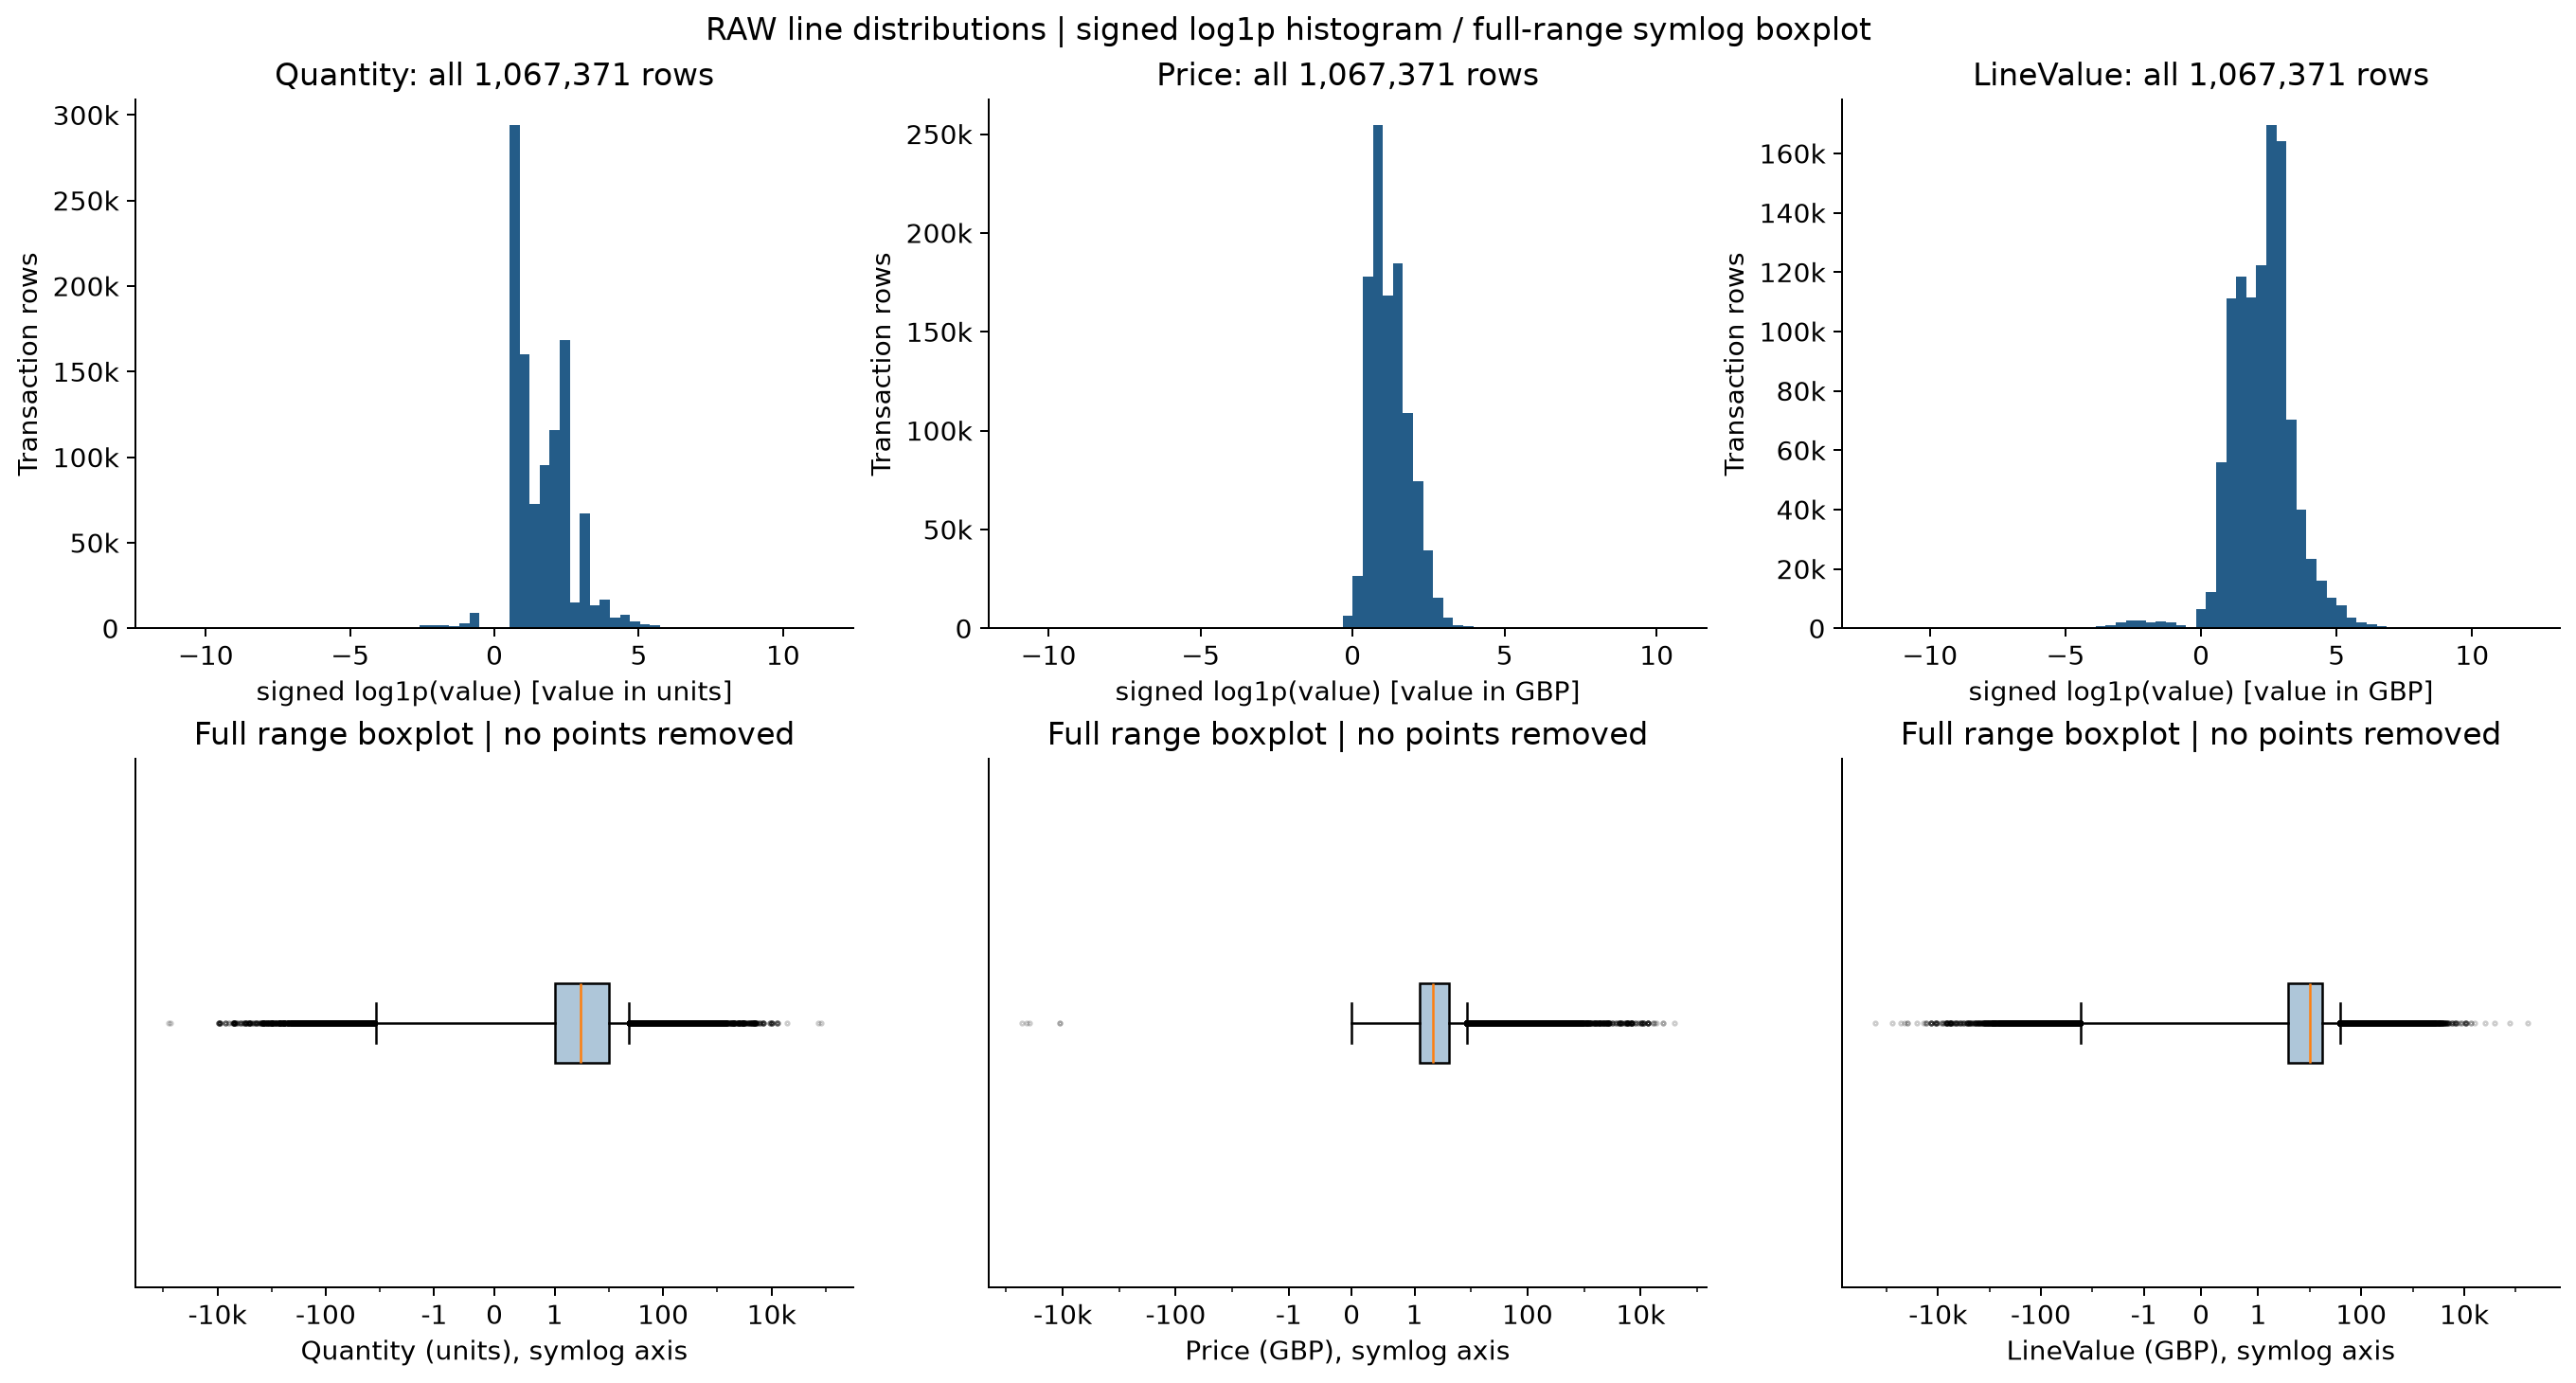

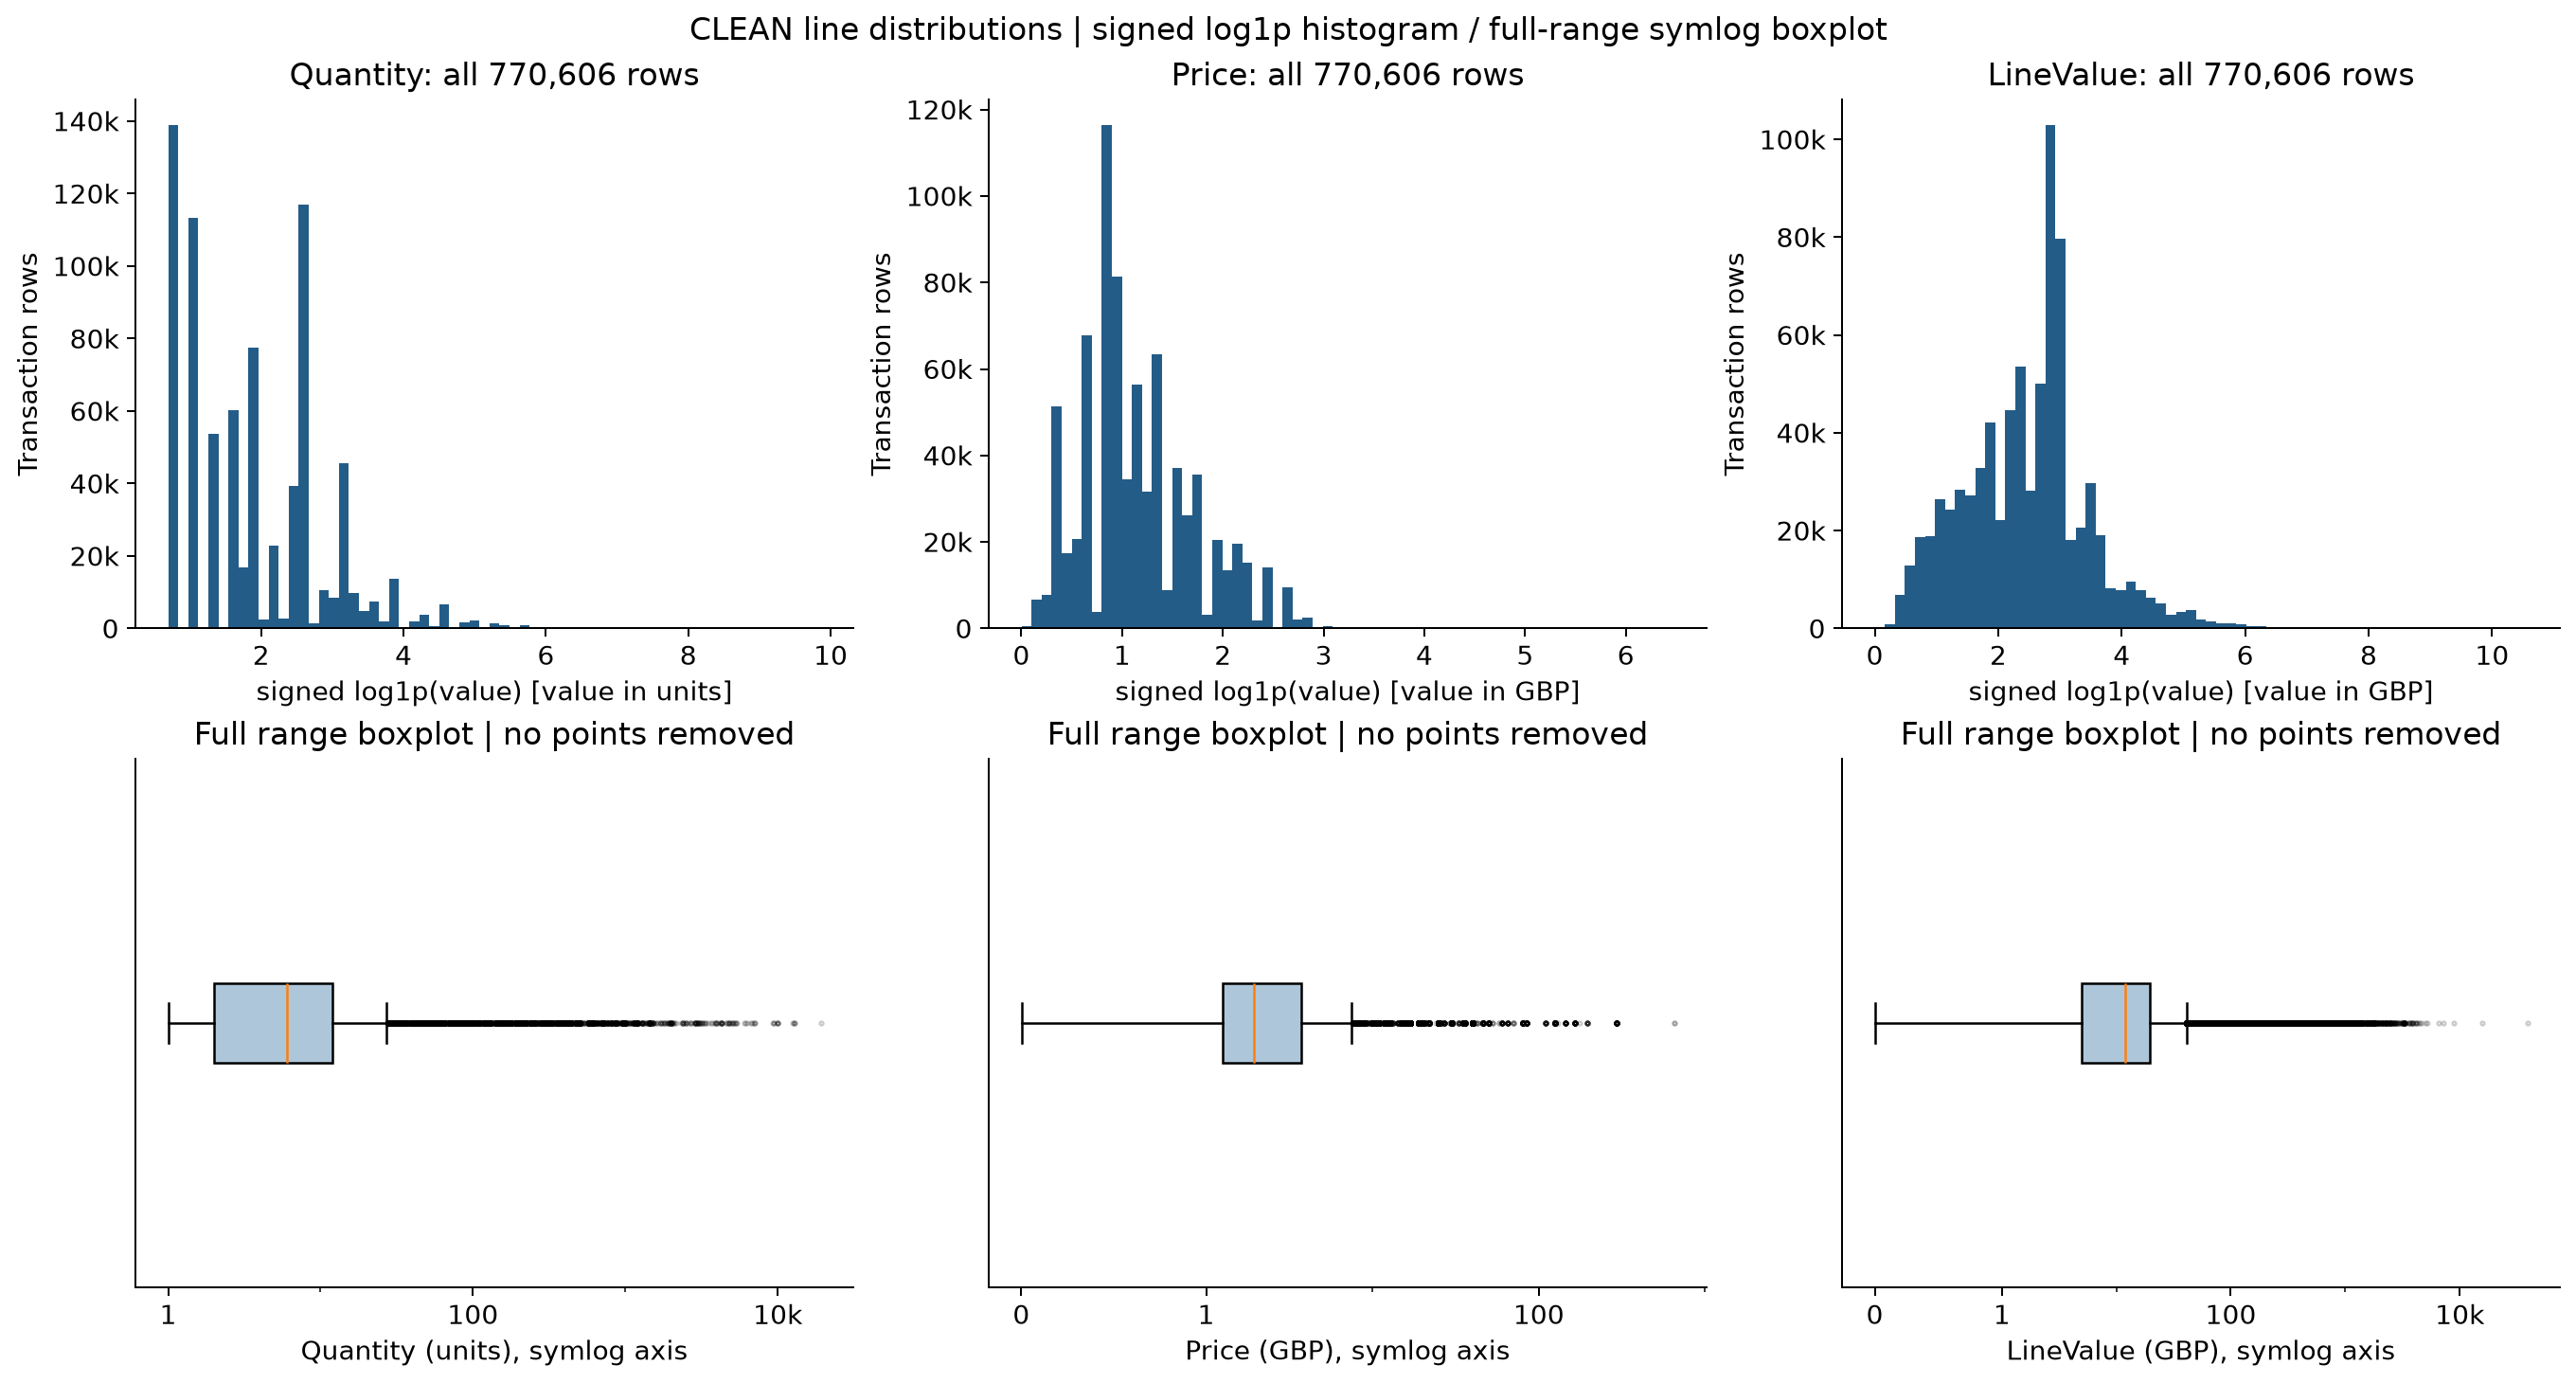

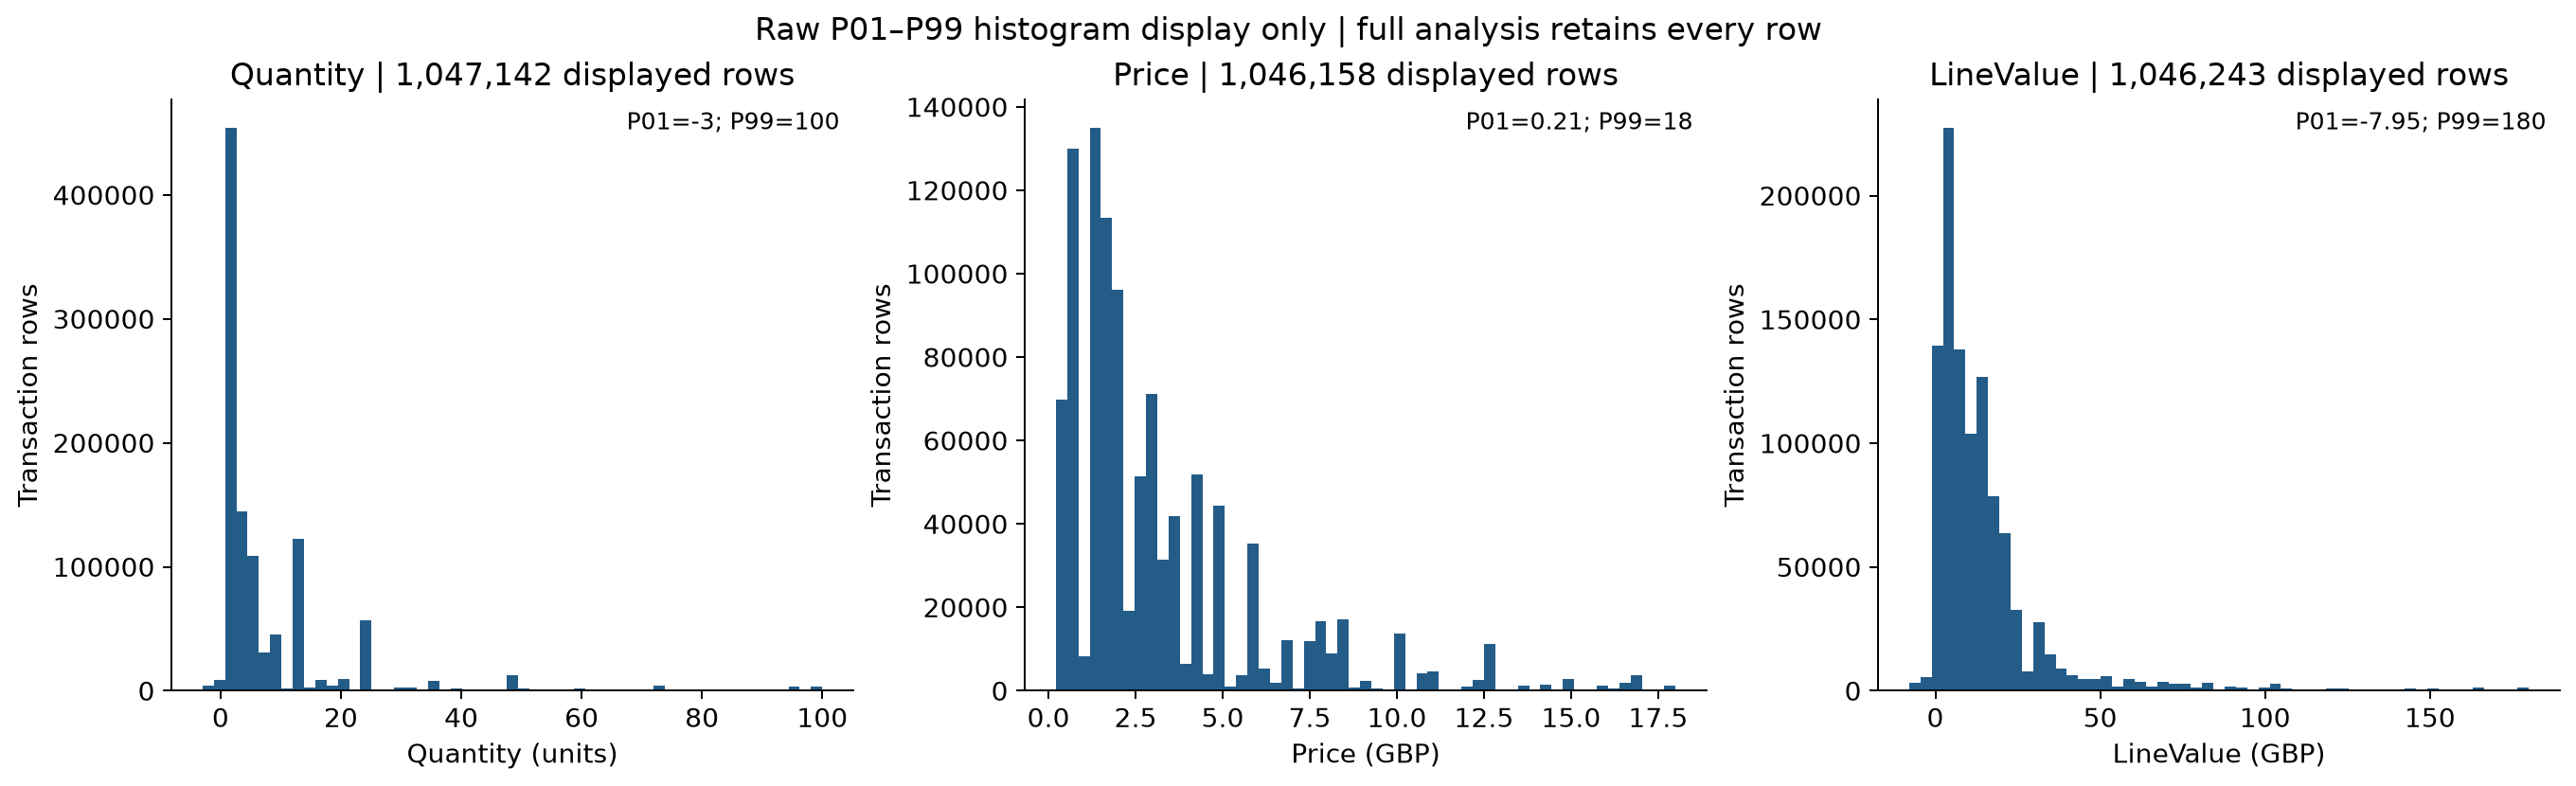

In [6]:
tables["descriptive_transactions"] = pd.concat([descriptive(raw, ["Quantity", "Price", "LineValue"], "raw_all_rows_including_C"),
                                                    descriptive(clean, ["Quantity", "Price", "LineValue"], "current_pipeline_sales")], ignore_index=True)
print("Building exploratory customer features and RFM (no model)...", flush=True)
purchase = clean.rename(columns={"CustomerID": "Customer ID"}).copy()
behavior = build_customer_behavior_features(purchase, window_start=WINDOW_START, reference_date=REFERENCE_DATE,
                                           stock_code_roles=None, invoice_time_policy="earliest", include_optional=True)
orders = aggregate_purchase_orders(purchase, window_start=WINDOW_START, reference_date=REFERENCE_DATE, invoice_time_policy="earliest")
purchase["Customer ID"] = identifier(purchase["Customer ID"])
totals = purchase.groupby("Customer ID").agg(total_purchase_value_rounded=("LineValue", "sum"), total_quantity_candidate=("Quantity", "sum"), n_stock_codes_candidate=("StockCode", "nunique"))
totals["total_purchase_value"] = (purchase.Quantity*purchase.Price).groupby(purchase["Customer ID"]).sum()
behavior = behavior.merge(totals, on="Customer ID", validate="one_to_one")
behavior["avg_quantity_per_order_candidate"] = behavior.total_quantity_candidate / behavior.n_orders
behavior["candidate_scope"] = "Codes retained by current service exclusion; not verified product catalog"
assert behavior["Customer ID"].is_unique
assert behavior.n_transaction_rows.sum() == len(clean)
assert behavior.n_orders.sum() == len(orders)
assert behavior.return_rate.isna().all()
assert behavior.loc[behavior.n_orders.eq(1), "avg_purchase_gap_days"].isna().all()
assert behavior.n_distinct_products.isna().all()
assert np.isclose(behavior.total_purchase_value.sum(), clean_exact_total)
assert np.allclose(behavior.avg_order_value * behavior.n_orders, behavior.total_purchase_value)
tables["customer_behavior"] = behavior
behavior_numeric = ["n_orders", "total_purchase_value", "avg_order_value", "n_stock_codes_candidate", "total_quantity_candidate", "avg_quantity_per_order_candidate", "avg_purchase_gap_days", "observed_tenure_days"]
tables["descriptive_customers"] = descriptive(behavior, behavior_numeric, "experimental_customers_from_current_pipeline")
singles = int(behavior.n_orders.eq(1).sum())
tables["customer_summary"] = pd.DataFrame([dict(customers=len(behavior), invoices=len(orders), single_invoice_customers=singles,
                                                single_invoice_pct=100*singles/len(behavior), denominator_customers=len(behavior),
                                                missing_purchase_gap=int(behavior.avg_purchase_gap_days.isna().sum()),
                                                multi_timestamp_orders=int(orders.n_timestamps.gt(1).sum()),
                                                orders_value_gbp=orders.order_value.sum(), exact_purchase_value_gbp=clean_exact_total,
                                                spearman_orders_value=behavior[["n_orders", "total_purchase_value"]].corr(method="spearman").iloc[0, 1])])
tables["outlier_transactions"] = tables["descriptive_transactions"].copy()
tables["outlier_customers"] = tables["descriptive_customers"].copy()
extremes = []
for variable in ["Quantity", "Price", "LineValue"]:
    for direction, frame in [("smallest", raw.nsmallest(5, variable)), ("largest", raw.nlargest(5, variable))]:
        extremes.append(frame[ORIGINAL_COLUMNS + ["Sheet", "LineValue"]].assign(variable=variable, direction=direction))
tables["extreme_rows"] = pd.concat(extremes, ignore_index=True)

table("descriptive_transactions",20)
table("outlier_transactions",20)

for dataset, frame in [("raw", raw), ("clean", clean)]:
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for i, variable in enumerate(["Quantity", "Price", "LineValue"]):
        values = frame[variable].to_numpy(float)
        transformed_values = np.sign(values)*np.log1p(np.abs(values))
        axes[0,i].hist(transformed_values, bins=65, color=BLUE)
        axes[0,i].set(title=f"{variable}: all {len(frame):,} rows", xlabel="signed log1p(value)" + (" [value in GBP]" if variable != "Quantity" else " [value in units]"), ylabel="Transaction rows")
        axes[1,i].boxplot(values, orientation="horizontal", patch_artist=True, boxprops={"facecolor":"#AEC6D9"}, flierprops={"markersize":1.5,"alpha":.2})
        axes[1,i].set_xscale("symlog", linthresh=1)
        low_axis, high_axis = axes[1,i].get_xlim()
        axes[1,i].set_xticks([value for value in [-1e6,-1e4,-1e2,-1,0,1,1e2,1e4,1e6] if low_axis <= value <= high_axis])
        count_format(axes[1,i], "x")
        axes[1,i].set(xlabel=f"{variable} ({'units' if variable == 'Quantity' else 'GBP'}), symlog axis", yticks=[], title="Full range boxplot | no points removed")
        count_format(axes[0,i])
    fig.suptitle(f"{dataset.upper()} line distributions | signed log1p histogram / full-range symlog boxplot")
    save(fig, f"{dataset}_transaction_full_distributions.png", f"{dataset} transaction full distributions", f"All {dataset} transaction rows, no outlier deletion", ["outlier_transactions"], "eda_v2_outlier.ipynb")
fig, axes = plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for ax, variable in zip(axes,["Quantity","Price","LineValue"]):
    low,high=raw[variable].quantile([.01,.99])
    displayed_values=raw.loc[raw[variable].between(low,high),variable]
    ax.hist(displayed_values,bins=55,color=BLUE)
    ax.set(title=f"{variable} | {len(displayed_values):,} displayed rows",xlabel=f"{variable} ({'units' if variable=='Quantity' else 'GBP'})",ylabel="Transaction rows")
    ax.text(.98,.98,f"P01={low:g}; P99={high:g}",ha="right",va="top",transform=ax.transAxes,fontsize=10)
fig.suptitle("Raw P01–P99 histogram display only | full analysis retains every row")
save(fig,"raw_transaction_histograms_p01_p99.png","Raw P01–P99 transaction histogram display","Raw rows restricted for display only, no data deletion",["outlier_transactions"],"eda_v2_outlier.ipynb")

**Kết quả:** trên 1,067,371 dòng thô, số điểm ngoài ngưỡng 1,5×IQR là
116,489 với Quantity,
68,105 với Price và
90,922 với LineValue.

**Cách đọc hình:** histogram signed log1p và boxplot symlog giữ toàn miền. Hình P01–P99
chỉ giới hạn hiển thị; không cắt dữ liệu tính toán. Những cờ này chưa chứng minh lỗi dữ liệu.

## 3. Kiểm tra ví dụ cực trị

Xem một số dòng lớn/âm thực tế cùng Invoice, StockCode, thời điểm và khách hàng. Ví dụ chỉ hỗ trợ điều tra, không đủ bằng chứng kết luận lỗi nhập liệu.

In [7]:
table("extreme_rows",18)

**extreme_rows** — 30 dòng kết quả.

Bảng giữ trong biến `tables["extreme_rows"]`; không xuất CSV trung gian.

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet,LineValue,variable,direction
0,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,2.0800,"16,446.0000",United Kingdom,Year 2010-2011,"-168,469.6000",Quantity,smallest
1,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,1.0400,"12,346.0000",United Kingdom,Year 2010-2011,"-77,183.6000",Quantity,smallest
2,519017,22759,NaN,-9600,2010-08-13 09:14:00,0.0000,NaN,United Kingdom,Year 2009-2010,-0.0000,Quantity,smallest
3,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0000,NaN,United Kingdom,Year 2010-2011,-0.0000,Quantity,smallest
4,556691,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,0.0000,NaN,United Kingdom,Year 2010-2011,-0.0000,Quantity,smallest
5,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.0800,"16,446.0000",United Kingdom,Year 2010-2011,"168,469.6000",Quantity,largest
6,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.0400,"12,346.0000",United Kingdom,Year 2010-2011,"77,183.6000",Quantity,largest
7,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,915.2000",Quantity,largest
8,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,296.0000",Quantity,largest
9,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.1000,"13,902.0000",Denmark,Year 2009-2010,"1,296.0000",Quantity,largest


Đang xem 18/30 dòng. Sau Run All, dùng `tables["extreme_rows"]` để xem đầy đủ.

**Ví dụ:** lượng lớn nhất có cặp chứng từ 581483 và C581484, tương ứng +80.995 và
−80.995 đơn vị. Hai dòng tương thích về khóa/lượng/thời điểm hỗ trợ điều tra sự kiện hủy,
nhưng chưa xác minh ý nghĩa nghiệp vụ hoặc chứng minh lỗi nhập liệu.

**Quyết định:** giữ ví dụ và cờ để đối chiếu; không tự xóa mọi giá trị âm hoặc cực lớn.
Pipeline hiện có không giải quyết đầy đủ liên kết hóa đơn gốc và hoàn trả một phần.

## 4. Phân phối ở cấp khách hàng

Mỗi khách hàng một quan sát: số hóa đơn, tổng Q×P, AOV và số StockCode ứng viên. Số mã hàng ứng viên không được gọi là sản phẩm đã xác nhận.

**outlier_customers** — 8 dòng kết quả.

Bảng giữ trong biến `tables["outlier_customers"]`; không xuất CSV trung gian.

,population,variable,count,median,q1,q3,iqr,p95,p99,maximum,outside_iqr,outside_iqr_pct
0,experimental_customers_from_current_pipeline,n_orders,5839,3.0000,1.0000,7.0000,6.0000,20.0000,46.0000,371.0000,423,7.2444
1,experimental_customers_from_current_pipeline,total_purchase_value,5839,851.0100,336.2450,"2,206.9450","1,870.7000","8,990.2870","26,811.0702","579,128.6400",616,10.5498
2,experimental_customers_from_current_pipeline,avg_order_value,5839,274.7600,174.5212,408.3463,233.8251,859.1934,"1,838.7700","19,809.7500",377,6.4566
3,experimental_customers_from_current_pipeline,n_stock_codes_candidate,5839,45.0000,19.0000,103.0000,84.0000,281.0000,502.6200,"2,507.0000",445,7.6212
4,experimental_customers_from_current_pipeline,total_quantity_candidate,5839,480.0000,188.0000,"1,344.0000","1,156.0000","5,259.6000","16,064.4800","365,114.0000",598,10.2415
5,experimental_customers_from_current_pipeline,avg_quantity_per_order_candidate,5839,154.0000,91.5357,258.0000,166.4643,548.5500,"1,296.7001","87,167.0000",358,6.1312
6,experimental_customers_from_current_pipeline,avg_purchase_gap_days,4226,72.9825,39.1898,131.2721,92.0823,323.9684,487.2278,714.1521,308,7.2882
7,experimental_customers_from_current_pipeline,observed_tenure_days,5839,529.4597,311.4979,666.5951,355.0972,735.5169,738.4247,738.6771,0,0.0000


**customer_summary** — 1 dòng kết quả.

Bảng giữ trong biến `tables["customer_summary"]`; không xuất CSV trung gian.

,customers,invoices,single_invoice_customers,single_invoice_pct,denominator_customers,missing_purchase_gap,multi_timestamp_orders,orders_value_gbp,exact_purchase_value_gbp,spearman_orders_value
0,5839,36414,1613,27.6246,5839,1613,64,"16,522,106.3070","16,522,106.3070",0.8580


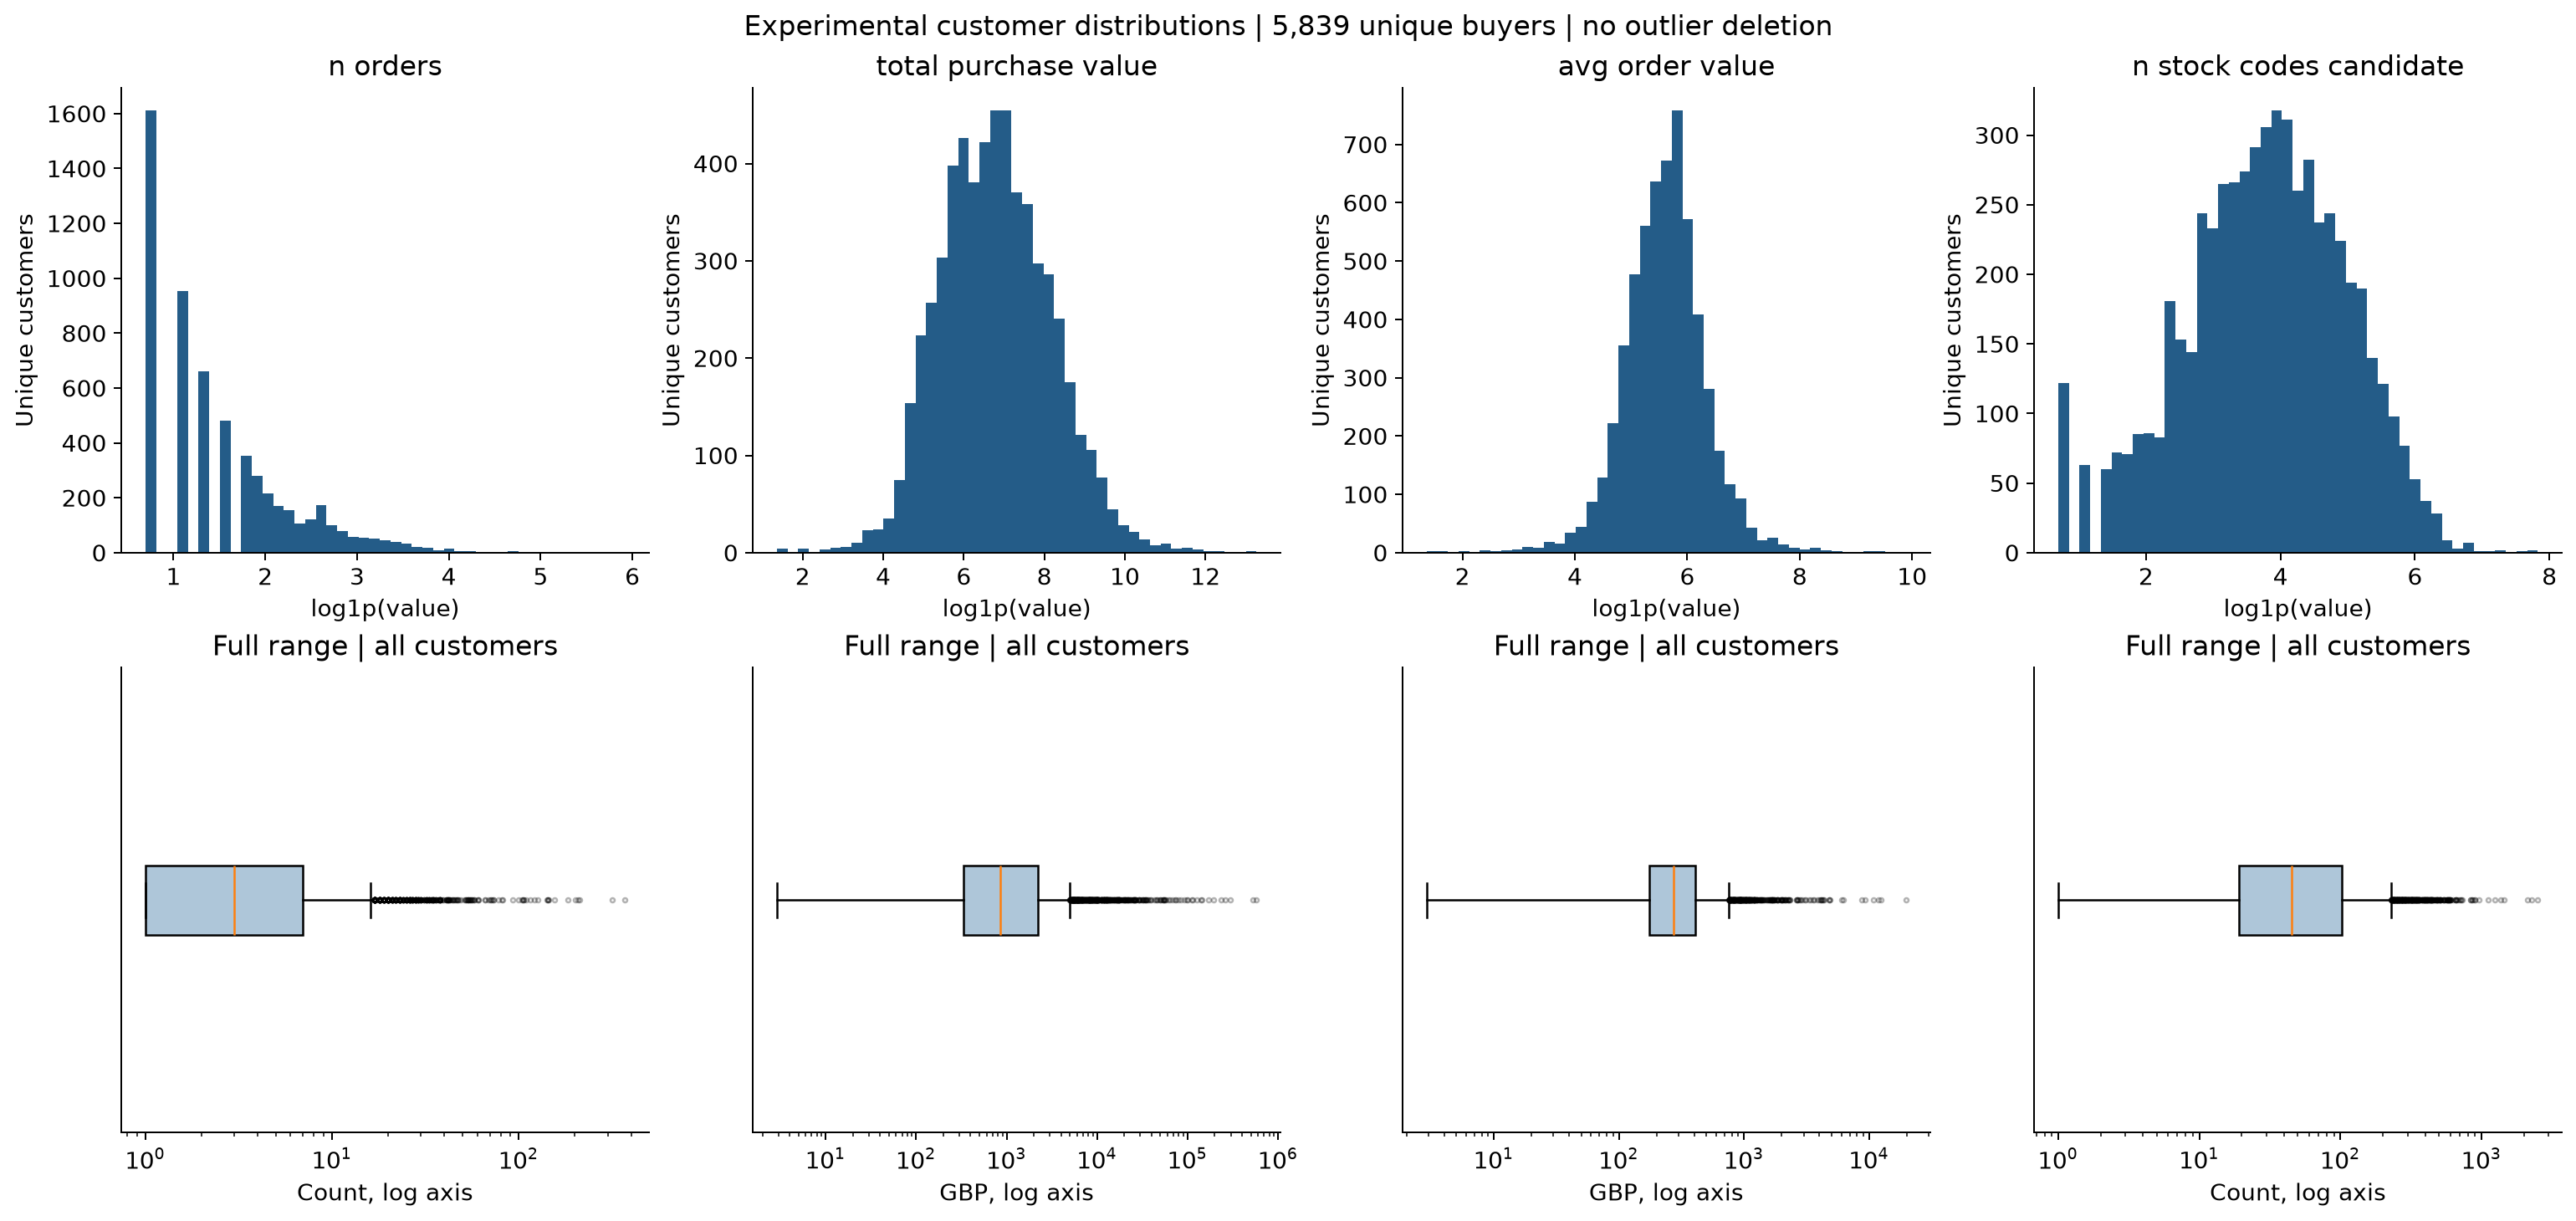

In [8]:
table("outlier_customers",20)
table("customer_summary")

customer_vars=["n_orders","total_purchase_value","avg_order_value","n_stock_codes_candidate"]
fig, axes=plt.subplots(2,4,figsize=(17,8),layout="constrained")
for i,col in enumerate(customer_vars):
    vals=behavior[col].to_numpy(float)
    axes[0,i].hist(np.log1p(vals),bins=45,color=BLUE)
    axes[0,i].set(title=col.replace("_"," "),xlabel="log1p(value)",ylabel="Unique customers")
    axes[1,i].boxplot(vals,orientation="horizontal",patch_artist=True,boxprops={"facecolor":"#AEC6D9"},flierprops={"markersize":2,"alpha":.3})
    axes[1,i].set_xscale("log")
    axes[1,i].set(xlabel=("GBP, log axis" if col in ["total_purchase_value","avg_order_value"] else "Count, log axis"),yticks=[],title="Full range | all customers")
fig.suptitle(f"Experimental customer distributions | {len(behavior):,} unique buyers | no outlier deletion")
save(fig,"customer_behavior_distributions.png","Customer behavior distributions","One row per current-pipeline buyer; stock counts unverified candidates",["outlier_customers"],"eda_v2_outlier.ipynb")

**Kết quả:** 616/5.839 khách (10,55%) vượt ngưỡng IQR của tổng giá trị mua;
423 khách vượt ngưỡng của số hóa đơn. Giá trị mua lớn nhất được giữ là 579.128,64 GBP.

**Ý nghĩa:** đuôi lớn có thể chi phối khoảng cách Euclid và tâm cụm. Khách ở đuôi có thể
chính là nhóm giá trị cao cần tìm, nên không loại chỉ vì IQR. Thử log1p/scaling và đánh
giá độ ổn định cụm là bước tiếp theo, **Cần nhóm xác nhận** với Thuận trước đổi chính sách.

AOV có trung vị 274,76 GBP/đơn và P99 ≈ 1.838,77 GBP/đơn. Trung vị, phân vị và max
giúp phân biệt một khách điển hình với các khách đuôi lớn; không dùng mean đơn lẻ.

## 5. Phần bổ sung sau EDA: RFM và scaling thử nghiệm

Cửa sổ [01/12/2009, 10/12/2011), mốc tham chiếu 10/12/2011 loại trừ. R là số ngày từ lần mua cuối quan sát; F là số Invoice mua duy nhất; M là tổng Q×P trong tập sau pipeline. Tất cả là khảo sát, chính sách **Cần nhóm xác nhận**.

**rfm** — 5,839 dòng kết quả.

Bảng giữ trong biến `tables["rfm"]`; không xuất CSV trung gian.

,Customer ID,Recency,Frequency,Monetary
0,12346,529.4215,2,169.3600
1,12347,2.3389,8,"4,921.5300"
2,12348,75.4493,5,"1,658.4000"
3,12349,18.5896,3,"3,678.6900"
4,12350,310.3326,1,294.4000
5,12351,375.3590,1,300.9300
6,12352,36.3910,9,"1,609.2100"
7,12353,204.2590,2,406.7600
8,12354,232.4507,1,"1,079.4000"
9,12355,214.4243,2,947.6100


Đang xem 10/5,839 dòng. Sau Run All, dùng `tables["rfm"]` để xem đầy đủ.

**rfm_profile** — 3 dòng kết quả.

Bảng giữ trong biến `tables["rfm_profile"]`; không xuất CSV trung gian.

,population,variable,count,missing,mean,median,minimum,maximum,std,skewness
0,experimental_RFM_full_observation_window,Recency,5839,0,200.2871,95.3632,0.4653,738.5493,208.6361,0.8939
1,experimental_RFM_full_observation_window,Frequency,5839,0,6.2363,3.0000,1.0000,371.0000,12.6765,11.9753
2,experimental_RFM_full_observation_window,Monetary,5839,0,"2,829.6123",851.0100,2.9000,"579,128.6400","13,900.5738",26.6115


**scaling_parameters** — 3 dòng kết quả.

Bảng giữ trong biến `tables["scaling_parameters"]`; không xuất CSV trung gian.

,feature,transform,scaler,mean_log1p,variance_log1p,scale_log1p,fit_customers,window_start,reference_date_exclusive
0,Recency,log1p,StandardScaler(ddof=0),4.4473,2.4378,1.5614,5839,2009-12-01,2011-12-10
1,Frequency,log1p,StandardScaler(ddof=0),1.5457,0.6511,0.8069,5839,2009-12-01,2011-12-10
2,Monetary,log1p,StandardScaler(ddof=0),6.7952,1.9007,1.3786,5839,2009-12-01,2011-12-10


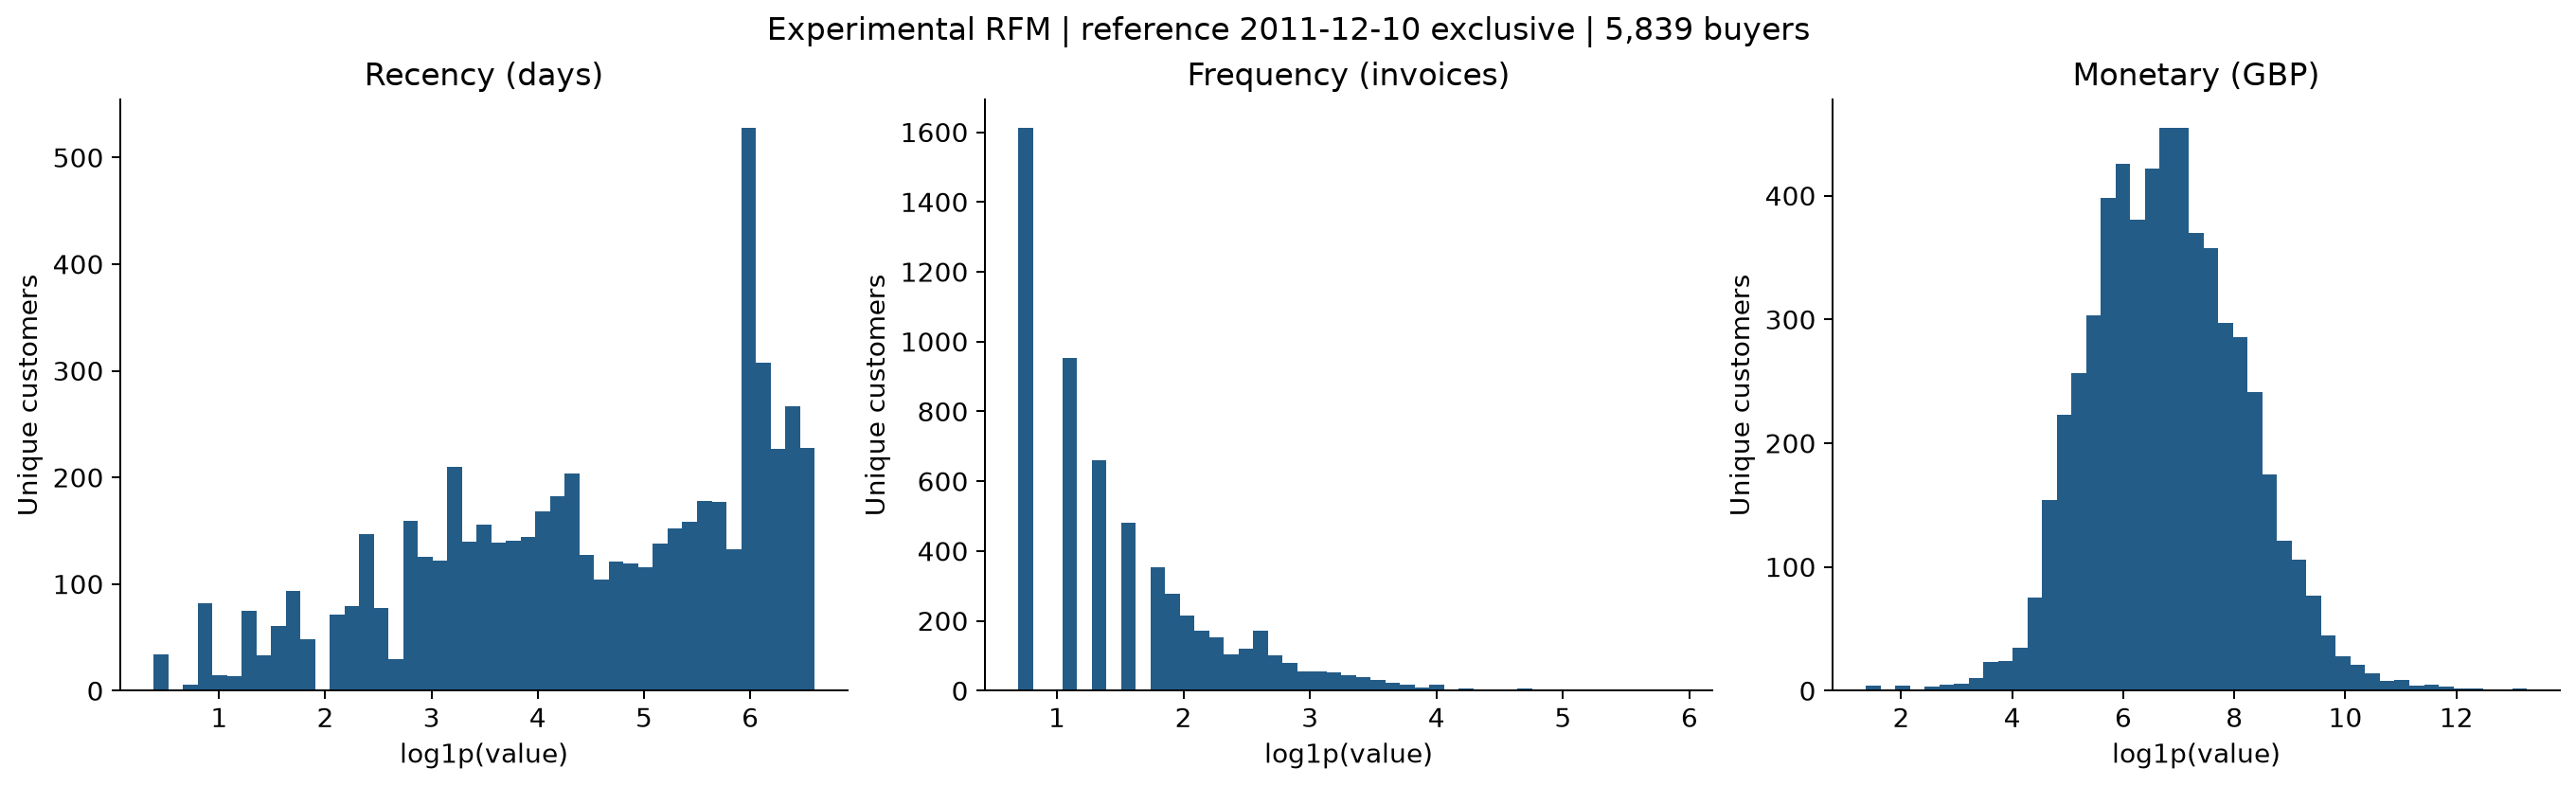

,feature,transform,scaler,mean_log1p,variance_log1p,scale_log1p,fit_customers,window_start,reference_date_exclusive
0,Recency,log1p,StandardScaler(ddof=0),4.4472707841817689,2.4378163993438196,1.5613508251971495,5839,2009-12-01,2011-12-10
1,Frequency,log1p,StandardScaler(ddof=0),1.5457059995631166,0.65111252595813607,0.8069154391620823,5839,2009-12-01,2011-12-10
2,Monetary,log1p,StandardScaler(ddof=0),6.7951831942629211,1.900672948886089,1.3786489578156178,5839,2009-12-01,2011-12-10


In [9]:
rfm = pd.DataFrame({"Customer ID": behavior["Customer ID"],
                    "Recency": (pd.Timestamp(REFERENCE_DATE)-pd.to_datetime(behavior.last_purchase_time)).dt.total_seconds()/86400,
                    "Frequency": behavior.n_orders, "Monetary": behavior.total_purchase_value})
assert rfm["Customer ID"].is_unique and rfm[["Recency", "Frequency", "Monetary"]].notna().all().all()
assert rfm.Recency.gt(0).all()
tables["rfm"] = rfm
tables["rfm_profile"] = descriptive(rfm, ["Recency", "Frequency", "Monetary"], "experimental_RFM_full_observation_window")
logged = np.log1p(rfm[["Recency", "Frequency", "Monetary"]])
scaler = StandardScaler()
scaled = scaler.fit_transform(logged)
transformed = rfm[["Customer ID"]].copy()
for i, col in enumerate(["Recency", "Frequency", "Monetary"]):
    transformed[f"log1p_{col}"] = logged[col]
    transformed[f"z_log1p_{col}"] = scaled[:, i]
tables["rfm_transformed"] = transformed
tables["scaling_parameters"] = pd.DataFrame({"feature": ["Recency", "Frequency", "Monetary"], "transform": "log1p", "scaler": "StandardScaler(ddof=0)",
                                               "mean_log1p": scaler.mean_, "variance_log1p": scaler.var_, "scale_log1p": scaler.scale_,
                                               "fit_customers": len(rfm), "window_start": WINDOW_START, "reference_date_exclusive": REFERENCE_DATE})

table("rfm",10)
table("rfm_profile",20)
table("scaling_parameters",20)

fig,axes=plt.subplots(1,3,figsize=(15,4.5),layout="constrained")
for ax,col,unit in zip(axes,["Recency","Frequency","Monetary"],["days","invoices","GBP"]):
    ax.hist(np.log1p(rfm[col]),bins=45,color=BLUE)
    ax.set(title=f"{col} ({unit})",xlabel="log1p(value)",ylabel="Unique customers")
fig.suptitle(f"Experimental RFM | reference {REFERENCE_DATE} exclusive | {len(rfm):,} buyers")
save(fig,"rfm_experimental_distributions.png","Experimental RFM distributions","Full observation-window buyers; no official feature designation; no model fitted",["rfm_profile","scaling_parameters"],"eda_v2_outlier.ipynb")

# Preserve exact fitted values in notebook output without a parameter file.
with pd.option_context("display.float_format", lambda value: format(value, ".17g")):
    display(tables["scaling_parameters"])

**Kết quả:** trung vị R ≈ 95,36 ngày, F = 3 hóa đơn và M = 851,01 GBP trên 5.839 khách.
Mốc tham chiếu là 10/12/2011, loại trừ; R dùng thời điểm mua theo chính sách hóa đơn,
F đếm Invoice duy nhất và M cộng Q×P chính xác của các dòng được giữ.

**Giới hạn:** log1p rồi StandardScaler được fit trên snapshot khảo sát, có lưu tham số.
Đây là chuẩn bị dữ liệu, chưa có kết quả mô hình hoặc bằng chứng phương án scale tốt nhất.
Với đánh giá theo thời gian, fit biến đổi trên tập phù hợp và không dùng hủy tương lai.

## 6. Kiểm tra và thông tin tái lập

Kết quả, checksum và phiên bản thư viện được giữ trong output notebook; không xuất JSON hay CSV riêng.

In [10]:
# Verify this independent EDA run without writing sidecar files.
assert checksum(source) == source_before
for relative, expected in {**code_before,**stored_hashes}.items():
    assert checksum(PROJECT / relative) == expected, relative
# Keep reproducibility information in saved notebook outputs, not JSON sidecars.
display(pd.DataFrame([
    {"input": "data/raw/online_retail_II.xlsx", "SHA256": source_before},
    *[{"input": name, "SHA256": digest} for name, digest in code_before.items()]
]))
versions = {"python": platform.python_version(), **{name: importlib.metadata.version(name)
            for name in ["pandas", "numpy", "matplotlib", "scikit-learn", "openpyxl"]}}
display(pd.Series(versions, name="version").to_frame())
assert behavior["Customer ID"].is_unique and rfm["Customer ID"].is_unique
assert behavior.return_rate.isna().all()
assert np.allclose(transformed.filter(like="z_log1p_").mean(),0,atol=1e-12)
assert np.allclose(transformed.filter(like="z_log1p_").std(ddof=0),1,atol=1e-12)
display(Markdown(f"**Hoàn thành độc lập:** {len(tables)} bảng trong notebook, không xuất CSV riêng, {len(figures)} PNG; "
                 f"{len(behavior):,} khách. Không đọc cache hoặc notebook khác."))

,input,SHA256
0,data/raw/online_retail_II.xlsx,bcbe73b35f5b7babf197fb0cb983a11f5d9ff929078d4aa53d171b1f2df2e980
1,src/preprocessing.py,301fc8fbca2beffa15c205cb278c740008992d6f09dd53730de7006b1d2c256e
2,src/features.py,9b65f8258129d6ca935566208fcd9812c7fdabebc203e4b5b53cb8b65bae71a3


,version
python,3.12.15
pandas,3.1.0
numpy,2.5.4
matplotlib,3.11.2
scikit-learn,1.9.1
openpyxl,3.1.5


**Hoàn thành độc lập:** 11 bảng trong notebook, không xuất CSV riêng, 5 PNG; 5,839 khách. Không đọc cache hoặc notebook khác.

### Bàn giao và phạm vi công việc

Các bảng ở biến `tables`, checksum, phiên bản và tham số scaling được giữ trong notebook.
Không tạo JSON hay CSV riêng cho lần chạy v2.

Kiểm tra chất lượng, phân phối và hành vi là EDA. Tạo RFM và fit StandardScaler là phần
bổ sung sau EDA đã được form ban đầu cho phép; chưa phải bảng chính thức hay mô hình phân cụm.
Nhóm cần chốt mua/hủy/phí/trùng, mã sản phẩm và cửa sổ trước bước mô hình hóa.
